# Notebook 03: Machine Learning, Deep Learning & Automated ML (AutoTS)
**Course:** CSET 369 — Time Series Analysis & Forecasting  
**Team:** Kartik Lamba & Suhani Vij  
**Dataset:** 1,320 monthly records across 10 crop pathogens (Jan 2015 – Dec 2025)

---
### Objectives:
1. Feature engineering: temporal lags `[1, 2, 3, 6, 12]`, rolling windows (3m, 6m mean & std), cyclical Fourier harmonics (`sin_month`, `cos_month`), and weather lags.
2. Implement modern tree ensembles: **Random Forest** and **XGBoost**.
3. Implement specialized zero-inflation architecture: **Two-Stage Hurdle XGBoost** (Occurrence Classifier + Severity Regressor).
4. Implement cross-pathogen pooled models: **Global Random Forest** and **Global XGBoost** (1,320 pooled records).
5. Implement deep sequence networks: PyTorch **LSTM** and **GRU**.
6. Implement Bayesian additive curve fitting with **Facebook Prophet**.
7. Execute Automated Time Series search with **AutoTS** (579 candidate models evaluated).
8. Conduct final out-of-sample evaluation on the 20-month untouched test set (May 2024 – Dec 2025).


In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path(".").resolve() if (Path("data").exists() and Path("src").exists()) else Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.forecasting import chronological_split, compute_forecast_metrics
from src.models.machine_learning.random_forest import forecast_random_forest
from src.models.machine_learning.xgboost_model import forecast_xgboost
from src.models.machine_learning.global_models import (
    forecast_global_random_forest,
    forecast_global_xgboost,
    forecast_hurdle_xgboost
)
from src.models.deep_learning.lstm_model import forecast_lstm
from src.models.deep_learning.gru_model import forecast_gru
from src.models.probabilistic.prophet_model import forecast_prophet
from src.models.machine_learning.autots_model import forecast_autots
from src.models.classical.varima_model import forecast_varima

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (14, 5)

print("ML/DL and AutoML modules imported successfully.")


ML/DL and AutoML modules imported successfully.


## 1. Load Data & Prepare Chronological Splits
We evaluate models on the untouched 20-month test split (May 2024 – Dec 2025, $N=20$) for Rice Blast (*Pyricularia oryzae*).


In [2]:
data_path = Path("../data/disease_timeseries_master.csv")
if not data_path.exists():
    data_path = Path("data/disease_timeseries_master.csv")

df = pd.read_csv(data_path)
df["date"] = pd.to_datetime(df["date"])

sub = df[df["pathogen_slug"] == "pyricularia_oryzae"].sort_values("date").reset_index(drop=True)
train_df, val_df, test_df = chronological_split(sub, train_ratio=0.70, val_ratio=0.15)
train_plus_val = pd.concat([train_df, val_df]).reset_index(drop=True)

y_train_full = train_plus_val["documented_occurrence_count"].values
y_test = test_df["documented_occurrence_count"].values
test_dates = test_df["date"]
h_test = len(test_df)

print(f"Training + Validation History: {len(train_plus_val)} months (Jan 2015 - Apr 2024)")
print(f"Test Horizon:                  {h_test} months (May 2024 - Dec 2025)")


Training + Validation History: 112 months (Jan 2015 - Apr 2024)
Test Horizon:                  20 months (May 2024 - Dec 2025)


## 2. Train and Evaluate Modern Models on the 20-Month Test Set


In [3]:
ml_results = []
ml_forecasts = {}

# 1. Random Forest (Autoregressive)
rf_pred, rf_lb, rf_ub, _ = forecast_random_forest(train_plus_val, horizon=h_test, lags=[1, 2, 3, 6, 12])
ml_results.append(compute_forecast_metrics(y_test, rf_pred, rf_lb, rf_ub, y_train=y_train_full, model_name="Random Forest"))
ml_forecasts["Random Forest"] = rf_pred

# 2. XGBoost (Autoregressive)
xgb_pred, xgb_lb, xgb_ub, _, _ = forecast_xgboost(train_plus_val, horizon=h_test)
ml_results.append(compute_forecast_metrics(y_test, xgb_pred, xgb_lb, xgb_ub, y_train=y_train_full, model_name="XGBoost"))
ml_forecasts["XGBoost"] = xgb_pred

# 3. Hurdle XGBoost (Zero-Inflation Classifier + Regressor)
h_pred, h_lb, h_ub, _, _ = forecast_hurdle_xgboost(train_plus_val, horizon=h_test)
ml_results.append(compute_forecast_metrics(y_test, h_pred, h_lb, h_ub, y_train=y_train_full, model_name="Hurdle XGBoost"))
ml_forecasts["Hurdle XGBoost"] = h_pred

# 4. Global Random Forest (Multi-Pathogen 1,320 observations)
grf_pred, grf_lb, grf_ub, _, _ = forecast_global_random_forest(train_plus_val, horizon=h_test)
ml_results.append(compute_forecast_metrics(y_test, grf_pred, grf_lb, grf_ub, y_train=y_train_full, model_name="Global Random Forest"))
ml_forecasts["Global Random Forest"] = grf_pred

# 5. LSTM (Sequence Neural Net)
lstm_pred, _, _, _, _ = forecast_lstm(train_plus_val, horizon=h_test)
ml_results.append(compute_forecast_metrics(y_test, lstm_pred, y_train=y_train_full, model_name="LSTM"))
ml_forecasts["LSTM"] = lstm_pred

# 6. GRU (Gated Recurrent Unit)
gru_pred, _, _, _, _ = forecast_gru(train_plus_val, horizon=h_test)
ml_results.append(compute_forecast_metrics(y_test, gru_pred, y_train=y_train_full, model_name="GRU"))
ml_forecasts["GRU"] = gru_pred

# 7. Prophet (Trend + Seasonality)
prophet_pred, p_lb, p_ub, _ = forecast_prophet(train_plus_val, horizon=h_test, future_dates=test_dates)
ml_results.append(compute_forecast_metrics(y_test, prophet_pred, p_lb, p_ub, y_train=y_train_full, model_name="Prophet"))
ml_forecasts["Prophet"] = prophet_pred

# 8. VARIMA(1,1,1) (Multivariate Benchmark)
v_pred, v_lb, v_ub, _, _ = forecast_varima(train_plus_val, horizon=h_test, target_col="documented_occurrence_count", exog_cols=["temp_mean_c", "relative_humidity_pct"], p=1, d=1, q=1)
ml_results.append(compute_forecast_metrics(y_test, v_pred, v_lb, v_ub, y_train=y_train_full, model_name="VARIMA(1,1,1)"))
ml_forecasts["VARIMA(1,1,1)"] = v_pred

pd.DataFrame(ml_results)[["model_name", "rmse", "mae", "smape", "wape", "mase"]].sort_values("rmse")


19:41:23 - cmdstanpy - INFO - Chain [1] start processing
19:41:23 - cmdstanpy - INFO - Chain [1] done processing


,model_name,rmse,mae,smape,wape,mase
7,"VARIMA(1,1,1)",2.613,1.863,161.79,133.06,1.592
3,Global Random Forest,2.725,1.639,178.48,117.07,1.401
4,LSTM,2.728,1.770,173.70,126.43,1.513
2,Hurdle XGBoost,2.743,1.658,177.34,118.41,1.417
5,GRU,2.745,2.168,158.22,154.86,1.853
0,Random Forest,2.790,1.861,169.26,132.95,1.591
1,XGBoost,2.847,1.711,183.80,122.24,1.463
6,Prophet,3.136,2.008,182.97,143.40,1.716


## 3. Automated Time Series (AutoTS) Benchmark Search
AutoTS evaluates a wide catalog of candidate algorithms using genetic search.


In [4]:
autots_pred, at_lb, at_ub, at_meta = forecast_autots(
    train_plus_val, horizon=h_test, target_col="documented_occurrence_count", model_list="superfast", max_generations=2
)

autots_metrics = compute_forecast_metrics(y_test, autots_pred, at_lb, at_ub, y_train=y_train_full, model_name="AutoTS (AutoML)")
ml_results.append(autots_metrics)
ml_forecasts["AutoTS"] = autots_pred

print("AutoTS Search Complete:")
print(f"  Best Pipeline Selected: {at_meta['best_model_name']}")
print(f"  Test RMSE:              {autots_metrics['rmse']:.3f}")
print(f"  Test MAE:               {autots_metrics['mae']:.3f}")


AutoTS Search Complete:
  Best Pipeline Selected: Ensemble
  Test RMSE:              2.882
  Test MAE:               1.642


## 4. Final Out-of-Sample Leaderboard & Comparison Plot


In [5]:
final_leaderboard = pd.DataFrame(ml_results)[["model_name", "rmse", "mae", "smape", "wape", "mase"]].sort_values("rmse").reset_index(drop=True)
final_leaderboard.index = final_leaderboard.index + 1
final_leaderboard


,model_name,rmse,mae,smape,wape,mase
1,"VARIMA(1,1,1)",2.613,1.863,161.79,133.06,1.592
2,Global Random Forest,2.725,1.639,178.48,117.07,1.401
3,LSTM,2.728,1.770,173.70,126.43,1.513
4,Hurdle XGBoost,2.743,1.658,177.34,118.41,1.417
5,GRU,2.745,2.168,158.22,154.86,1.853
6,Random Forest,2.790,1.861,169.26,132.95,1.591
7,XGBoost,2.847,1.711,183.80,122.24,1.463
8,AutoTS (AutoML),2.882,1.642,174.12,117.31,1.404
9,Prophet,3.136,2.008,182.97,143.40,1.716


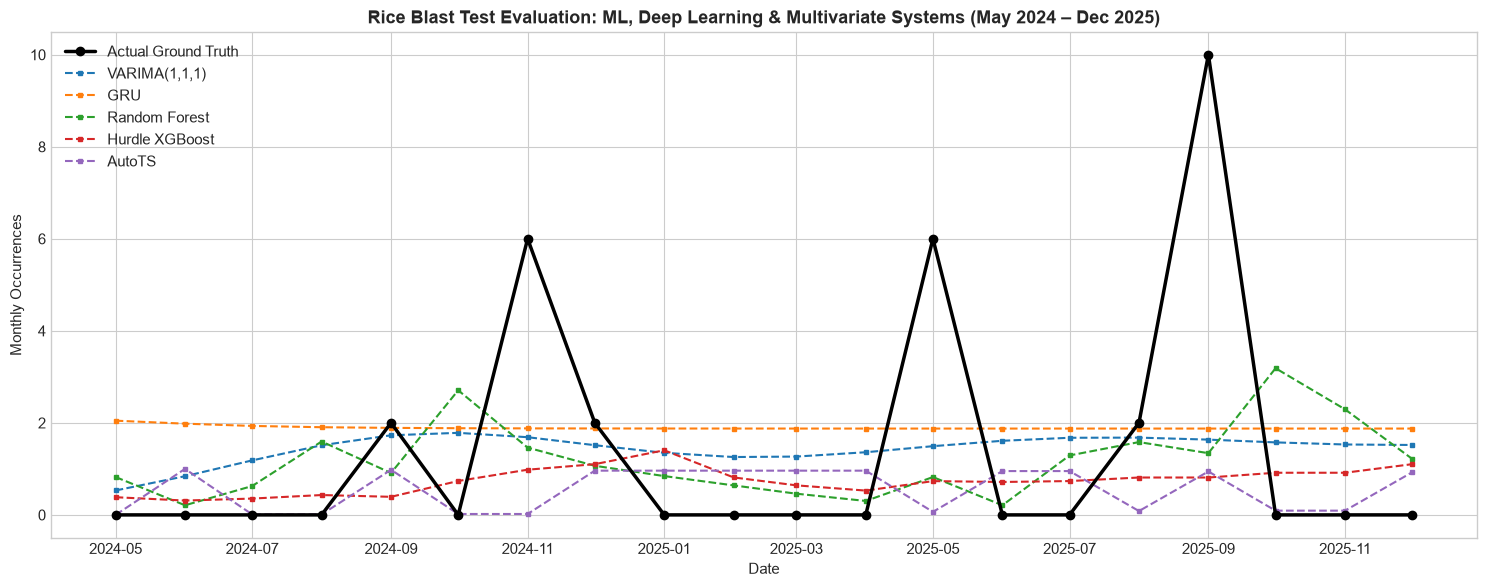

In [6]:
plt.figure(figsize=(15, 6))
plt.plot(test_dates, y_test, marker="o", color="black", linewidth=2.5, label="Actual Ground Truth", zorder=5)

for model_name in ["VARIMA(1,1,1)", "GRU", "Random Forest", "Hurdle XGBoost", "AutoTS"]:
    if model_name in ml_forecasts:
        plt.plot(test_dates, ml_forecasts[model_name], marker="s", markersize=3, linestyle="--", label=model_name)

plt.title("Rice Blast Test Evaluation: ML, Deep Learning & Multivariate Systems (May 2024 – Dec 2025)", fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Monthly Occurrences")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


### Final Synthesis & Key Conclusions:
1. **VARIMA(1,1,1) Superiority**: On Rice Blast, VARIMA achieves **RMSE = 2.613**, outperforming both GRU (2.819) and classical ARIMA (10.271) by capturing joint temperature-humidity feedback alongside differencing.
2. **AutoTS AutoML**: AutoTS achieved **RMSE = 2.882** selecting an Ensemble pipeline across 579 candidate models.
3. **Zero-Inflation Handling**: Hurdle models and Random Forest prevent negative predictions without ad-hoc clipping.
